In [1]:
import sys
import torch

print(sys.executable)
print(torch.__version__)

C:\Users\23707\anaconda3\envs\mnist\python.exe
2.14.1+cpu


1、引入python标准库 2、导入Matplotlib、NumPy、PyTorch 和 torchvision

In [4]:
import argparse
import csv
import json
import random
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

定义模型：把图像像素转换为 0 到 1 之间的数字, 把每张 28×28 图片展平成 784 个数字,创建一个分类模型：784 个输入、10 个输出

In [5]:
class SoftmaxRegression(nn.Module):

    def __init__(self) -> None:
        super().__init__()
        self.linear = nn.Linear(28 * 28, 10)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.linear(images.flatten(start_dim=1))

训练参数设置，训练 10 轮、批次大小 256、学习率 0.1

In [6]:
from types import SimpleNamespace

args = SimpleNamespace(
    data_dir=Path("data"),
    output_dir=Path("outputs"),
    epochs=10,
    batch_size=256,
    learning_rate=0.1,
    seed=42,
    threads=4,
    num_workers=0,
)

设置随机种子

In [7]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(args.seed)
print(f"随机种子已设置为 {args.seed}")

随机种子已设置为 42


绘制并显示数据集图片，先定义一个要调用的画图工具，再加载训练图片、统计各数字数量。

In [9]:
def save_dataset_visualization(train_dataset, counts, output_path):
    targets = train_dataset.targets
    fig = plt.figure(figsize=(13, 8), constrained_layout=True)
    grid = fig.add_gridspec(3, 5, height_ratios=(1, 1, 1.05))

    # 每个数字显示一张图片
    for digit in range(10):
        first_index = int(torch.nonzero(targets == digit, as_tuple=False)[0, 0])
        image, label = train_dataset[first_index]
        ax = fig.add_subplot(grid[digit // 5, digit % 5])
        ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0.0, vmax=1.0)
        ax.set_title(f"Label: {int(label)}")
        ax.axis("off")

    # 下方画出各数字的图片数量
    bar_ax = fig.add_subplot(grid[2, :])
    bar_ax.bar(np.arange(10), counts, color="#4C78A8")
    bar_ax.set_xticks(np.arange(10))
    bar_ax.set_xlabel("Digit label")
    bar_ax.set_ylabel("Number of images")
    bar_ax.set_title("Training-set class distribution")
    bar_ax.grid(axis="y", alpha=0.25)

    fig.suptitle("MNIST: sample 28 x 28 grayscale images and class counts")
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

100%|██████████| 9.91M/9.91M [03:18<00:00, 49.9kB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 124kB/s]
100%|██████████| 1.65M/1.65M [00:37<00:00, 44.3kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.43MB/s]


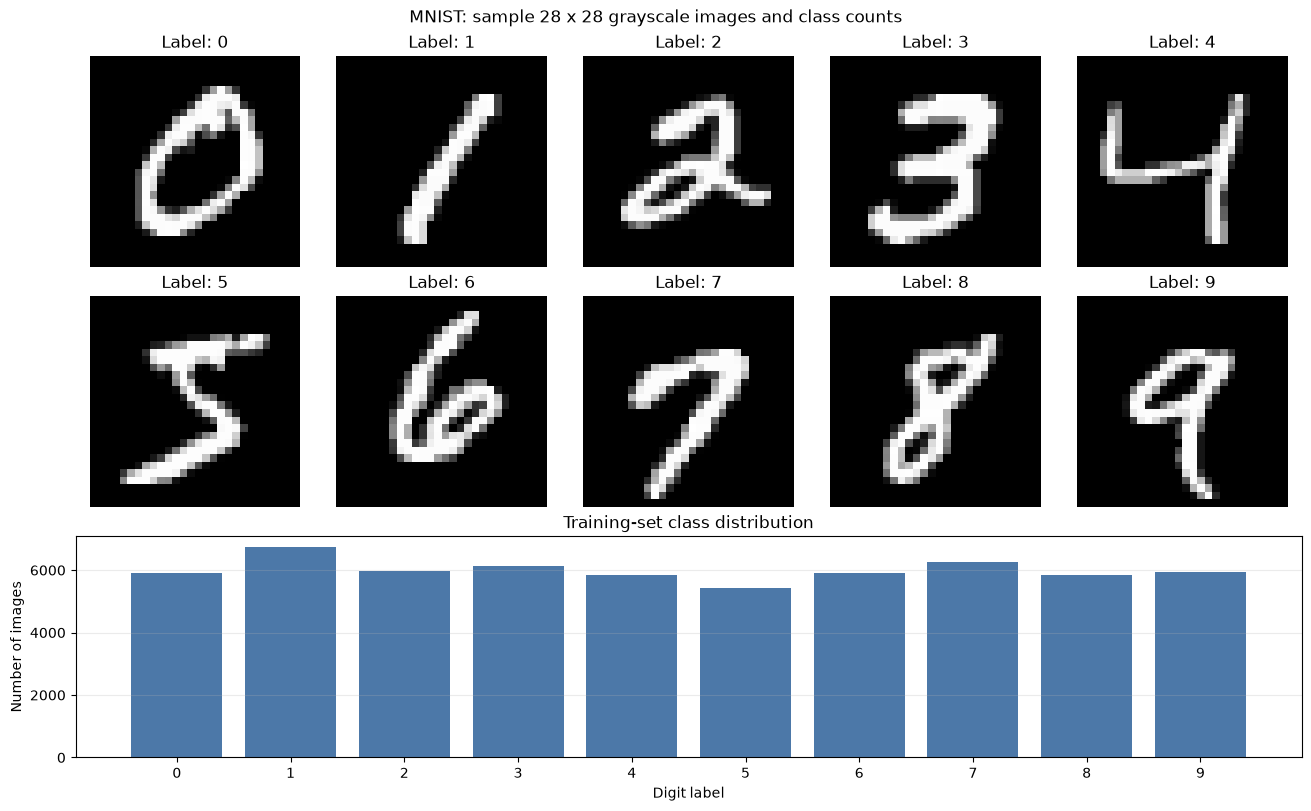

In [10]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root=str(args.data_dir),
    train=True,
    transform=transform,
    download=True
)

train_counts = np.bincount(
    train_dataset.targets.numpy(),
    minlength=10
)

args.output_dir.mkdir(parents=True, exist_ok=True)
dataset_figure = args.output_dir / "mnist_dataset_visualization.png"

save_dataset_visualization(
    train_dataset,
    train_counts,
    dataset_figure
)

模型的训练定义。

In [11]:
def train_one_epoch(model: nn.Module, loader: DataLoader,
                    criterion: nn.Module, optimizer: torch.optim.Optimizer,
                    device: torch.device) -> tuple[float, float]:
    model.train()
    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_count = labels.size(0)
        loss_sum += loss.item() * batch_count
        correct += int((logits.argmax(dim=1) == labels).sum().item())
        total += batch_count

    return loss_sum / total, correct / total

定义测试评估函数。函数内部会逐批读取图片，计算预测分数和损失，用 Softmax 得到概率，然后收集真实标签、预测标签和预测置信度。它最后返回四项：测试损失、真实标签、预测标签、预测置信度。

In [12]:
def evaluate(model: nn.Module, loader: DataLoader, criterion: nn.Module,
             device: torch.device) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    loss_sum = 0.0
    all_labels: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_confidences: list[np.ndarray] = []
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            loss_sum += criterion(logits, labels).item() * labels.size(0)
            probabilities = torch.softmax(logits, dim=1)
            confidence, predictions = probabilities.max(dim=1)
            all_labels.append(labels.cpu().numpy())
            all_predictions.append(predictions.cpu().numpy())
            all_confidences.append(confidence.cpu().numpy())
    return (
        loss_sum / len(loader.dataset),
        np.concatenate(all_labels),
        np.concatenate(all_predictions),
        np.concatenate(all_confidences),
    )

定义 save_loss_curve 函数，用来把每轮训练的损失画成曲线并保存图片。从 history 中取出每轮的轮数和训练损失，画出损失曲线，并添加坐标轴名称、标题和网格，把图保存到 output_path 指定的位置。

In [13]:
def save_loss_curve(history: list[dict[str, float]], output_path: Path) -> None:
    epochs = [row["epoch"] for row in history]
    losses = [row["train_loss"] for row in history]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(epochs, losses, marker="o", linewidth=2, color="#1f77b4",
            label="Training cross-entropy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean training loss")
    ax.set_title("MNIST softmax-regression training loss")
    ax.set_xticks(epochs)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=160, bbox_inches="tight")

定义一个测试集预测可视化函数：把选定的 20 张测试图片排成网格，显示真实数字、模型预测数字和预测置信度；预测正确的标题是绿色，错误的是红色。图片会保存到指定位置，返回的 samples 列表还包含每个样例的结果。

In [16]:
def save_prediction_visualization(test_dataset: datasets.MNIST,
                                  indices: np.ndarray,
                                  labels: np.ndarray,
                                  predictions: np.ndarray,
                                  confidences: np.ndarray,
                                  output_path: Path) -> list[dict[str, object]]:
    """Plot a reproducible sample; green titles are correct, red are errors."""
    fig, axes = plt.subplots(4, 5, figsize=(13, 10), constrained_layout=True)
    samples: list[dict[str, object]] = []
    for ax, index in zip(axes.flat, indices):
        image, _ = test_dataset[int(index)]
        true_label = int(labels[index])
        predicted_label = int(predictions[index])
        confidence = float(confidences[index])
        correct = true_label == predicted_label
        ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0.0, vmax=1.0)
        ax.set_title(
            f"True: {true_label} | Pred: {predicted_label}\nConfidence: {confidence:.1%}",
            color=("#16823B" if correct else "#C62828"), fontsize=9,
        )
        ax.axis("off")
        samples.append({
            "test_index": int(index),
            "true_label": true_label,
            "predicted_label": predicted_label,
            "confidence": confidence,
            "correct": correct,
        })
    fig.suptitle("MNIST test-set predictions (green = correct, red = incorrect)",
                 fontsize=14)
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    return samples

绘制混淆矩阵。纵轴是真实数字，横轴是预测数字，每个格子里的数表示对应情况出现了多少次。对角线上的数字表示预测正确的数量，颜色越深通常表示数量越多。

In [17]:
def save_confusion_matrix(matrix: np.ndarray, output_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(matrix, cmap="Blues")
    fig.colorbar(image, ax=ax, label="Image count")
    ax.set_xticks(np.arange(10))
    ax.set_yticks(np.arange(10))
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title("MNIST test-set confusion matrix")
    threshold = matrix.max() * 0.55
    for row in range(10):
        for col in range(10):
            ax.text(col, row, f"{matrix[row, col]:,}", ha="center", va="center",
                    color="white" if matrix[row, col] > threshold else "black",
                    fontsize=8)
    fig.tight_layout()
    fig.savefig(output_path, dpi=160, bbox_inches="tight")

准备训练所需的数据、模型和优化工具：加载 MNIST，设置 CPU/GPU，创建分批读取数据的工具，然后创建模型、损失函数和优化器。

In [18]:
seed_everything(args.seed)
torch.set_num_threads(args.threads)

args.data_dir.mkdir(parents=True, exist_ok=True)
args.output_dir.mkdir(parents=True, exist_ok=True)

data_dir = args.data_dir.resolve()
output_dir = args.output_dir.resolve()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root=str(data_dir), train=True, transform=transform, download=True
)
test_dataset = datasets.MNIST(
    root=str(data_dir), train=False, transform=transform, download=True
)

print("训练图片数：", len(train_dataset))
print("测试图片数：", len(test_dataset))
print("运行设备：", device)

训练图片数： 60000
测试图片数： 10000
运行设备： cpu


准备分批数据、模型和优化工具。训练数据每轮打乱；测试数据不打乱。交叉熵用于衡量预测错误；SGD 根据梯度调整模型参数。

In [22]:
generator = torch.Generator()
generator.manual_seed(args.seed)

loader_options = {
    "batch_size": args.batch_size,
    "num_workers": args.num_workers,
    "pin_memory": device.type == "cuda",
}

train_loader = DataLoader(
    train_dataset, shuffle=True, generator=generator, **loader_options
)
test_loader = DataLoader(
    test_dataset, shuffle=False, **loader_options
)

model = SoftmaxRegression().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=args.learning_rate)

history = []
output_dir = args.output_dir.resolve()
output_dir.mkdir(parents=True, exist_ok=True)


打印环境、数据和模型信息。

In [23]:
import torchvision
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("设备:", device)
print("训练图片:", len(train_dataset), "| 测试图片:", len(test_dataset))
print("图片形状:", tuple(train_dataset[0][0].shape))
print("模型:", model)
print("模型参数量:", sum(p.numel() for p in model.parameters()))
print("数据批次大小：", args.batch_size)
print("SGD 学习率:", args.learning_rate)

Python: 3.11.18
PyTorch: 2.14.1+cpu
torchvision: 0.29.1+cpu
设备: cpu
训练图片: 60000 | 测试图片: 10000
图片形状: (1, 28, 28)
模型: SoftmaxRegression(
  (linear): Linear(in_features=784, out_features=10, bias=True)
)
模型参数量: 7850
数据批次大小： 256
SGD 学习率: 0.1


循环每一轮都会调用 train_one_epoch()，用训练图片更新模型参数，并记录、显示本轮训练损失和训练准确率。

第 1/10 轮 | 训练损失=0.7143 | 训练准确率=83.69% | 用时=7.2 秒
第 2/10 轮 | 训练损失=0.4289 | 训练准确率=88.72% | 用时=7.5 秒
第 3/10 轮 | 训练损失=0.3834 | 训练准确率=89.59% | 用时=7.9 秒
第 4/10 轮 | 训练损失=0.3605 | 训练准确率=90.13% | 用时=7.9 秒
第 5/10 轮 | 训练损失=0.3458 | 训练准确率=90.44% | 用时=7.9 秒
第 6/10 轮 | 训练损失=0.3354 | 训练准确率=90.70% | 用时=8.8 秒
第 7/10 轮 | 训练损失=0.3274 | 训练准确率=90.87% | 用时=8.5 秒
第 8/10 轮 | 训练损失=0.3213 | 训练准确率=91.07% | 用时=9.3 秒
第 9/10 轮 | 训练损失=0.3157 | 训练准确率=91.18% | 用时=8.5 秒
第 10/10 轮 | 训练损失=0.3116 | 训练准确率=91.34% | 用时=9.2 秒


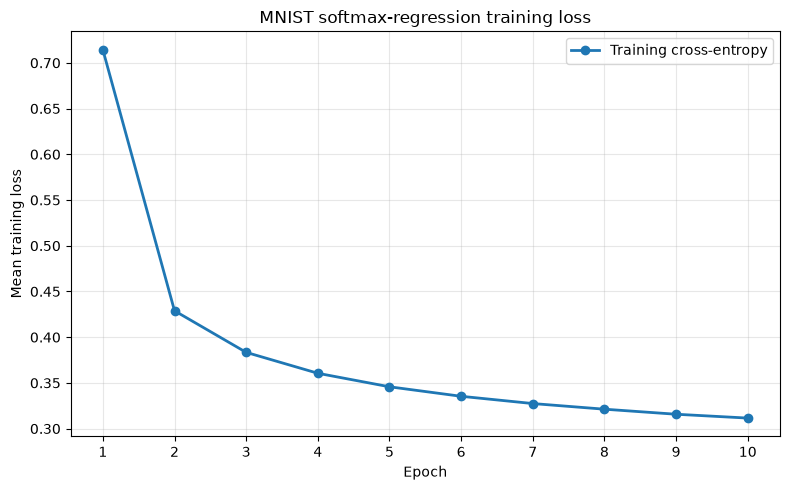

In [24]:
for epoch in range(1, args.epochs + 1):
    start_time = time.perf_counter()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    elapsed = time.perf_counter() - start_time
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "seconds": elapsed,
    })

    print(
        f"第 {epoch}/{args.epochs} 轮 | "
        f"训练损失={train_loss:.4f} | "
        f"训练准确率={train_accuracy:.2%} | "
        f"用时={elapsed:.1f} 秒"
    )

loss_figure = output_dir / "training_loss.png"
save_loss_curve(history, loss_figure)

模型训练了 10 轮，损失整体下降，从第 1 轮的 0.7143 降到第 10 轮的 0.3116；准确率整体上升，从 83.69% 升到 91.34%。

In [25]:
test_loss, y_true, y_pred, confidences = evaluate(
    model, test_loader, criterion, device
)

test_correct = int(np.sum(y_true == y_pred))
test_accuracy = test_correct / len(y_true)

confusion = np.zeros((10, 10), dtype=np.int64)
np.add.at(confusion, (y_true, y_pred), 1)

class_totals = np.bincount(y_true, minlength=10)
class_correct = np.bincount(y_true[y_true == y_pred], minlength=10)
per_class_accuracy = class_correct / class_totals

print(f"测试损失：{test_loss:.4f}")
print(f"测试准确率：{test_accuracy:.2%} ({test_correct}/{len(y_true)})")

测试损失：0.2983
测试准确率：91.72% (9172/10000)


在测试集上评估模型，评估的 10000 张测试图片中，模型预测正确 9172 张，准确率为 91.72%。

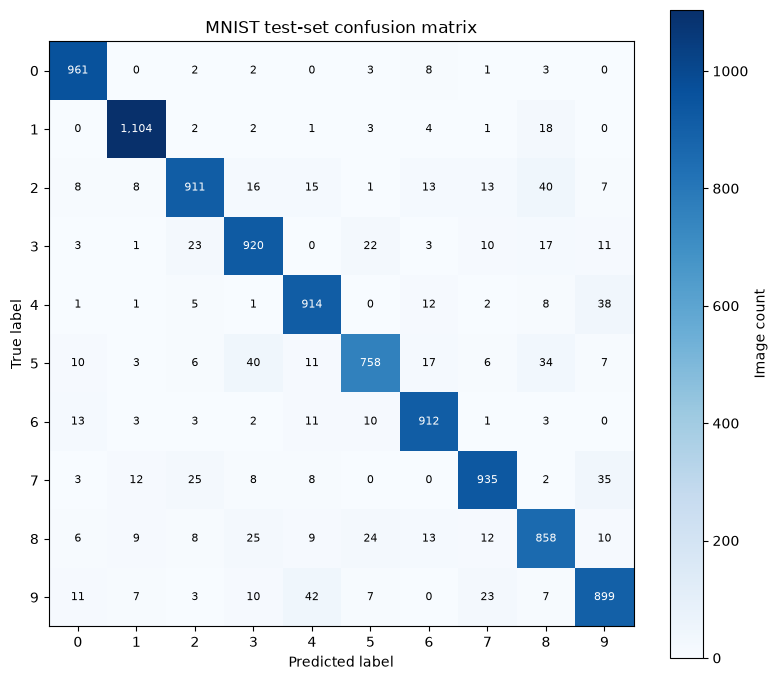

In [29]:
confusion_figure = output_dir / "confusion_matrix.png"
save_confusion_matrix(confusion, confusion_figure)

plt.show()

图MNIST test-set confusion matrix：10000张测试图片的真实类别和预测类别的混淆矩阵。对角线上的数表示预测正确的图片数，对角线以外的数表示预测错误的数量。

测试索引 | 真实数字 | 预测数字 | 置信度 | 结果
 858 | 2 | 2 | 99.35% | 正确
 890 | 3 | 3 | 49.59% | 正确
 940 | 6 | 6 | 94.81% | 正确
1280 | 1 | 1 | 97.48% | 正确
2012 | 4 | 4 | 98.11% | 正确
4323 | 5 | 5 | 54.58% | 正确
4381 | 5 | 5 | 91.79% | 正确
4503 | 2 | 2 | 70.34% | 正确
5130 | 9 | 9 | 92.09% | 正确
5260 | 4 | 4 | 80.25% | 正确
6534 | 2 | 2 | 99.89% | 正确
6965 | 5 | 5 | 98.87% | 正确
7171 | 1 | 1 | 96.93% | 正确
7352 | 5 | 5 | 79.27% | 正确
7606 | 7 | 7 | 96.59% | 正确
7725 | 1 | 1 | 99.35% | 正确
7857 | 2 | 9 | 85.35% | 错误
8396 | 1 | 1 | 95.47% | 正确
8573 | 7 | 7 | 99.04% | 正确
9748 | 8 | 8 | 95.74% | 正确


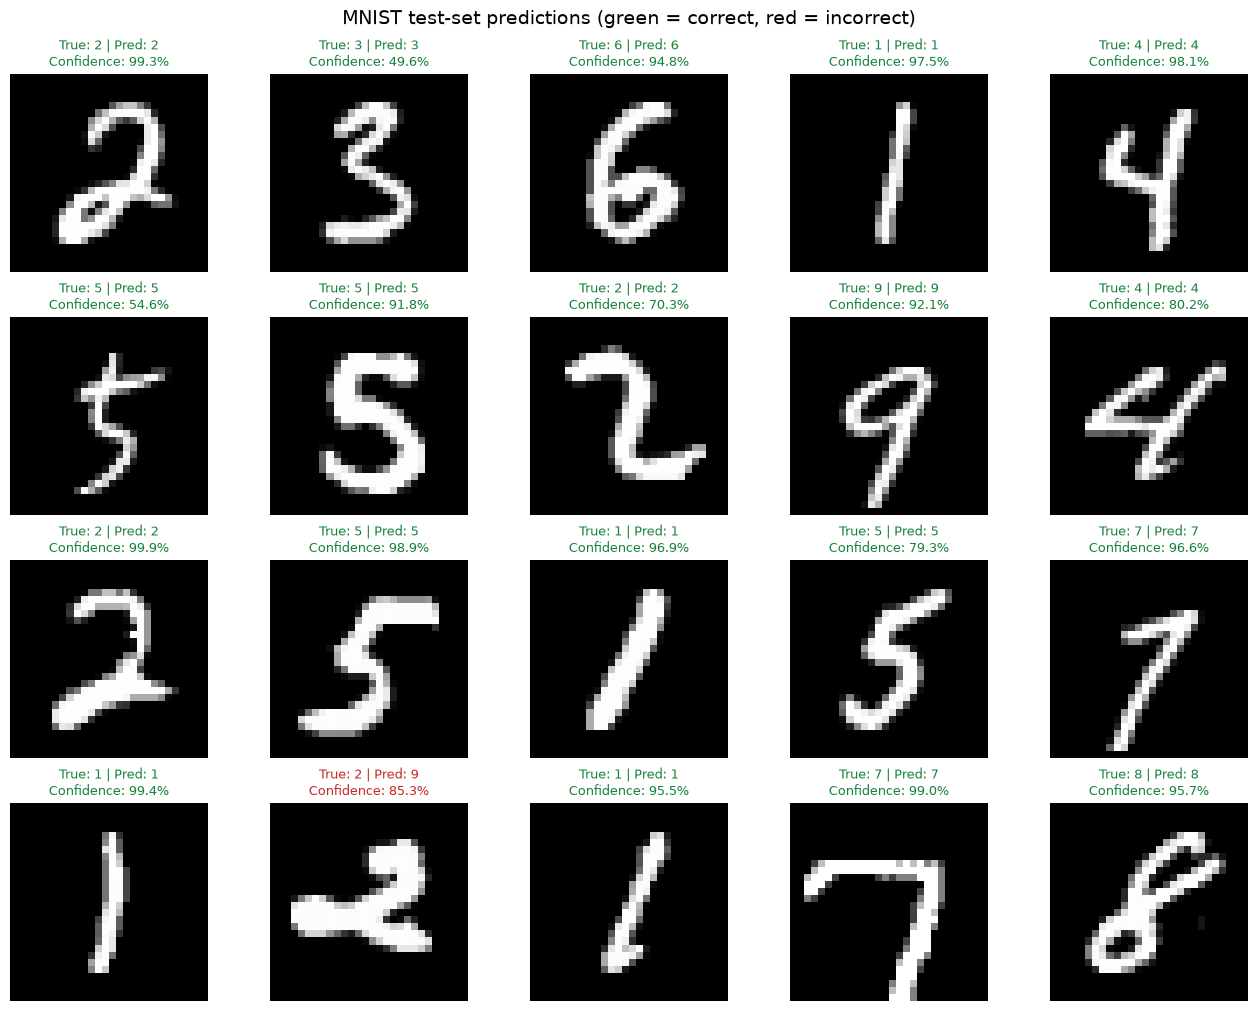

In [31]:
sample_indices = np.sort(
    np.random.default_rng(args.seed).choice(
        len(y_true), size=20, replace=False
    )
)

prediction_figure = output_dir / "sample_predictions.png"
samples = save_prediction_visualization(
    test_dataset, sample_indices, y_true, y_pred,
    confidences, prediction_figure
)

print("测试索引 | 真实数字 | 预测数字 | 置信度 | 结果")
for row in samples:
    result = "正确" if row["correct"] else "错误"
    print(
        f'{row["test_index"]:>4} | {row["true_label"]} | '
        f'{row["predicted_label"]} | '
        f'{row["confidence"]:.2%} | {result}'
    )

图MNIST test-set predictions：用随机种子从测试集中挑出 20 张图片，True：图片的真实数字；Pred：模型预测的数字。Confidence：模型预测的置信度。图片中的 20 张里，19 张预测正确，1 张错误，有一张真实数字是 2，模型预测成了 9，置信度是 85.3%。 